<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/Actividad_EDA_predictivo_bank_marketing_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Gizeh Gutierrez

**Matrícula:** 271752
**Fecha:** 7 Octubre 2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | |
| ¿Qué se predice? | |
| ¿Qué tipo de problema es? | |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | |
| ¿Qué columnas no deberían usarse como características y por qué? | |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Escribe tu respuesta aquí, antes de ejecutar la celda de código.
**Espero que aproximadamente entre el 10% y el 20% de los contactos hayan terminado en la contratación del depósito. Utilizaré como predicción inicial un 15% de contrataciones.**

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**creo que no se tendran muchos valores NaN, ya que los datos faltantes suelen registrarse mediante la categoría "unknown" en lugar de valores nulos.**

**Se podrian encontrar registros "unknown" principalmente en las variables job, marital, education, default, housing y loan. probablemente education sea la columna con mayor cantidad de estos registros, aprox entre 1,500 y 2,500 filas.**

In [2]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

# Dimensiones del conjunto
print("Dimensiones del conjunto:")
print(df.shape)

# el tipo de dato de cada columna
print("\nTipos de dato por columna:")
print(df.dtypes)

# el número de valores únicos por columna, de menor a mayor
print("\nValores únicos por columna:")
valores_unicos = df.nunique().sort_values()
print(valores_unicos)

Dimensiones del conjunto:
(41188, 21)

Tipos de dato por columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Valores únicos por columna:
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      26


In [3]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

# el total de valores NaN del conjunto
total_nan = df.isna().sum().sum()

print("Total de valores NaN en el conjunto:", total_nan)

# conteo como porcentaje de las filas
unknown_counts = {}

for col in categoricas:
    conteo = (df[col] == "unknown").sum()
    if conteo > 0:
        unknown_counts[col] = conteo

if unknown_counts:
    unknown_df = pd.DataFrame({
        "Filas con 'unknown'": pd.Series(unknown_counts),
        "Porcentaje": pd.Series(unknown_counts) / len(df) * 100
    }).sort_values("Filas con 'unknown'", ascending=False)

    print("\nColumnas categóricas con valores 'unknown':")
    print(unknown_df.round(2))
else:
    print("\nNo se encontraron valores 'unknown' en las variables categóricas.")

Total de valores NaN en el conjunto: 0

Columnas categóricas con valores 'unknown':
           Filas con 'unknown'  Porcentaje
default                   8597       20.87
education                 1731        4.20
housing                    990        2.40
loan                       990        2.40
job                        330        0.80
marital                     80        0.19


In [4]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
# Conteo de filas completamente duplicadas
duplicados = df.duplicated().sum()

print("Número de filas completamente idénticas:", duplicados)


Número de filas completamente idénticas: 12


In [5]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

#filas tienen pdays igual a 999
pdays_999 = (df["pdays"] == 999).sum()
porcentaje_pdays_999 = pdays_999 / len(df) * 100

print("Filas con pdays = 999:", pdays_999)
print(f"Porcentaje: {porcentaje_pdays_999:.2f}%")

# tabla de contingencia entre poutcome y (previous == 0)
print("\nTabla de contingencia: poutcome vs (previous == 0)")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))

# tabla de contingencia entre poutcome y (pdays == 999)
print("\nTabla de contingencia: poutcome vs (pdays == 999)")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays = 999: 39673
Porcentaje: 96.32%

Tabla de contingencia: poutcome vs (previous == 0)
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Tabla de contingencia: poutcome vs (pdays == 999)
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [6]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.
# la edad mínima y máxima
print("Edad mínima:", df["age"].min())
print("Edad máxima:", df["age"].max())

# cuántas llamadas tienen duration igual a 0
duration_cero = (df["duration"] == 0).sum()
print("\nLlamadas con duration = 0:", duration_cero)

# el mínimo y el máximo de campaign
print("\nMínimo de campaign:", df["campaign"].min())
print("Máximo de campaign:", df["campaign"].max())

# cuántas filas tienen previous negativo
previous_negativo = (df["previous"] < 0).sum()
print("\nFilas con previous negativo:", previous_negativo)

Edad mínima: 17
Edad máxima: 98

Llamadas con duration = 0: 4

Mínimo de campaign: 1
Máximo de campaign: 56

Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.  

**No se encontraron valores NaN. Los datos faltantes están representados por la categoría "unknown", principalmente en default 8,597, education 1,731, housing 990, loan 990, job 330 y marital 80. Se identificaron 12 filas duplicadas.**

**El valor pdays = 999 aparece en 39,673 registros 96.32% y representa clientes no contactados previamente, por lo que no se considera un error.**

**Existe una relación consistente entre previous, pdays y poutcome: cuando previous = 0, poutcome = nonexistent, y la mayoría de los casos con pdays = 999 también presentan poutcome = nonexistent.**

**La variable age tiene valores entre 17 y 98 años, sin registros fuera de un rango razonable. Solo 4 llamadas presentan duration = 0. La variable campaign varía entre 1 y 56 contactos. No se encontraron valores negativos en previous, por lo que la variable es consistente con su definición.**

**La predicción fue correcta: no se encontraron valores NaN y los datos faltantes están codificados como "unknown". También se identificaron correctamente las variables afectadas education, default, housing, loan, job y marital. Solo la cantidad, "unknown" en default fue 20.87%.**

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

**La recomendación sería mantener "unknown" como una categoría válida y no eliminar registros. Eliminar las filas afectadas implicaría perder 8,597 registros 20.87%. Conservar esta categoría permite mantener toda la información disponible y evaluar después si la ausencia de información tiene valor predictivo.**

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

 **si, creo que la proporción de contratación sera prácticamente la misma en los conjuntos de entrenamiento y prueba, ya que la división conserva la distribución original de las clases (yes y no). Por ello, cualquier diferencia entre ambos porcentajes debería ser mínima.**

In [7]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.

# División entrenamiento-prueba (80%-20%) estratificada
entrenamiento, prueba = train_test_split(
    df,
    test_size=0.20,
    stratify=df["y"],
    random_state=42
)

# Copia del conjunto de entrenamiento
ent = entrenamiento.copy()

# Variable binaria objetivo
ent["suscribe"] = np.where(ent["y"] == "yes", 1, 0)

# Tamaño de los conjuntos
print("Tamaño de entrenamiento:", entrenamiento.shape)
print("Tamaño de prueba:", prueba.shape)

# Porcentaje de contratación
pct_ent = (entrenamiento["y"] == "yes").mean() * 100
pct_prueba = (prueba["y"] == "yes").mean() * 100

print(f"\nPorcentaje de contratación en entrenamiento: {pct_ent:.2f}%")
print(f"Porcentaje de contratación en prueba: {pct_prueba:.2f}%")

Tamaño de entrenamiento: (32950, 21)
Tamaño de prueba: (8238, 21)

Porcentaje de contratación en entrenamiento: 11.27%
Porcentaje de contratación en prueba: 11.26%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [8]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

**La predicción fue correcta. La proporción de contratación fue prácticamente igual en ambos conjuntos: 11.27% en entrenamiento y 11.26% en prueba. La diferencia de 0.01  confirma que la división conservó la distribución de la variable objetivo y que el conjunto de prueba es representativo del de entrenamiento.**

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Si un modelo predijera siempre "no", tendría una exactitud de mas de 80%, equivalente a la proporción de clientes que no contrataron el depósito. Sin embargo, no identificaría correctamente ningún caso de contratación.**

Número de clientes por clase:
y
no     29238
yes     3712
Name: count, dtype: int64

Porcentaje de clientes por clase:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Razón clase mayoritaria/minoritaria: 7.88

Exactitud de responder siempre 'no': 88.73%


/tmp/ipykernel_1517/510647125.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=ent, x="y", palette=COLORES_CLASE)


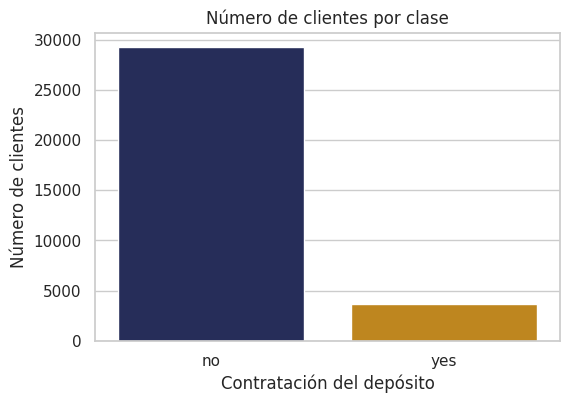

In [ ]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.

# Número y porcentaje de clientes por clase
conteo_clases = ent["y"].value_counts()
porcentaje_clases = ent["y"].value_counts(normalize=True) * 100

print("Número de clientes por clase:")
print(conteo_clases)

print("\nPorcentaje de clientes por clase:")
print(porcentaje_clases.round(2))

# Razón entre la clase mayoritaria y la minoritaria
razon = conteo_clases.max() / conteo_clases.min()
print(f"\nRazón clase mayoritaria/minoritaria: {razon:.2f}")

# Exactitud de responder siempre 'no'
exactitud_no = (ent["y"] == "no").mean() * 100
print(f"\nExactitud de responder siempre 'no': {exactitud_no:.2f}%")

# Gráfica de barras
plt.figure(figsize=(6, 4))
sns.countplot(data=ent, x="y", palette=COLORES_CLASE)
plt.title("Número de clientes por clase")
plt.xlabel("Contratación del depósito")
plt.ylabel("Número de clientes")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

**La proporción de clientes que contrataron el depósito fue 11.27%, mientras que el 88.73% no lo hizo. Ademas, un modelo que siempre predijera "no" alcanzaría una exactitud cerca al 88.73%.**

**Esto evidencia un desbalance importante entre clases, por lo que la exactitud por sí sola no es suficiente para evaluar el modelo. Seriá necesario considerar métricas como precisión, recall, F1-score y la matriz de confusión para medir adecuadamente la capacidad de detectar la clase minoritaria (yes).**

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero  que duration tenga valores más altos en los clientes que contratan el depósito. También se prevén diferencias en previous y pdays, ya que el historial de contacto puede influir en la decisión de contratación. Las variables económicas euribor3m y emp.var.rate podrían mostrar diferencias moderadas entre clases. En contraste, se espera que age y campaign presenten diferencias menores entre quienes contratan y quienes no.**

Mediana de las variables numéricas por clase:
      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1


/tmp/ipykernel_1094/1675116441.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x="y", y="duration", ax=axes[0], palette=COLORES_CLASE)
/tmp/ipykernel_1094/1675116441.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x="y", y="campaign", ax=axes[1], palette=COLORES_CLASE)
/tmp/ipykernel_1094/1675116441.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x="y", y="age", ax=axes[2], palette=COLORES_CLASE)


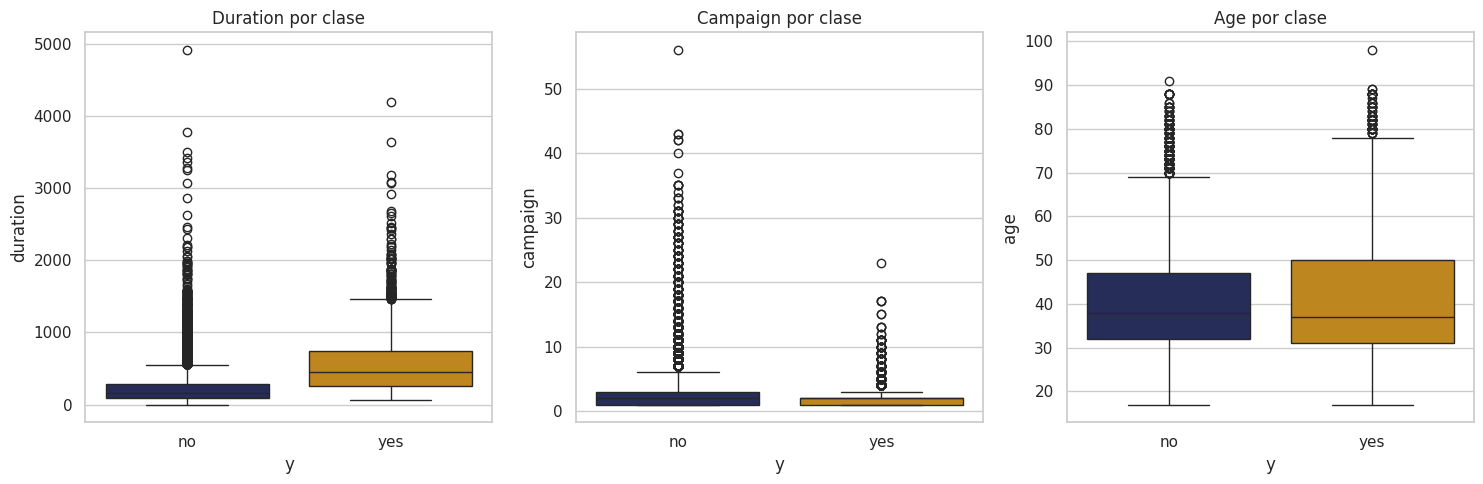

In [9]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
# Mediana de cada variable numérica por clase de y
medianas = ent.groupby("y")[numericas].median()

print("Mediana de las variables numéricas por clase:")
print(medianas)

# Diagramas de caja para tres variables numéricas
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=ent, x="y", y="duration", ax=axes[0], palette=COLORES_CLASE)
axes[0].set_title("Duration por clase")

sns.boxplot(data=ent, x="y", y="campaign", ax=axes[1], palette=COLORES_CLASE)
axes[1].set_title("Campaign por clase")

sns.boxplot(data=ent, x="y", y="age", ax=axes[2], palette=COLORES_CLASE)
axes[2].set_title("Age por clase")

plt.tight_layout()
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

**Las variables que más separan las clases son duration y las variables económicas (euribor3m, nr.employed, emp.var.rate, cons.price.idx y cons.conf.idx). En cambio, age, campaign, pdays y previous muestran poca diferencia entre clases.**

**La predicción fue parcialmente correcta ya que duration y las variables económicas sí presentaron diferencias importantes, pero previous y pdays no mostraron la separación esperada.**

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero que duration, campaign y previous sean las variables con más valores atípicos, debido a que presentan distribuciones sesgadas y algunos registros con valores mucho mayores que la mayoría de los casos.**

In [10]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

resultados = []

for col in numericas:
    Q1 = ent[col].quantile(0.25)
    Q3 = ent[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    fuera = ((ent[col] < limite_inferior) | (ent[col] > limite_superior)).sum()

    resultados.append([
        col,
        round(limite_inferior, 2),
        round(limite_superior, 2),
        fuera
    ])

atipicos = pd.DataFrame(
    resultados,
    columns=["Variable", "Límite inferior", "Límite superior", "Registros fuera"]
)

print(atipicos.sort_values("Registros fuera", ascending=False))

         Variable  Límite inferior  Límite superior  Registros fuera
4        previous             0.00             0.00             4534
1        duration          -221.00           643.00             2366
2        campaign            -2.00             6.00             1916
3           pdays           999.00           999.00             1226
0             age             9.50            69.50              368
7   cons.conf.idx           -52.15           -26.95              359
5    emp.var.rate            -6.60             6.20                0
6  cons.price.idx            91.70            95.37                0
8       euribor3m            -4.08            10.39                0
9     nr.employed          4905.60          5421.60                0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

**No eliminaría los valores atípicos. En age, duration, campaign y previous representan casos reales y útiles para la predicción. por lo que mantendria los registros.**

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero que np.log1p(campaign) reduzca más la asimetría que np.sqrt(campaign), porque comprime más los valores altos. Por ello, espero que el logaritmo produzca una distribución más cercana a la simetría.**

Asimetría de las variables:
          Original  Raiz_cuadrada  Log1p
age          0.761          0.426  0.132
duration     3.327          1.204 -0.430
campaign     4.743          2.163  1.351


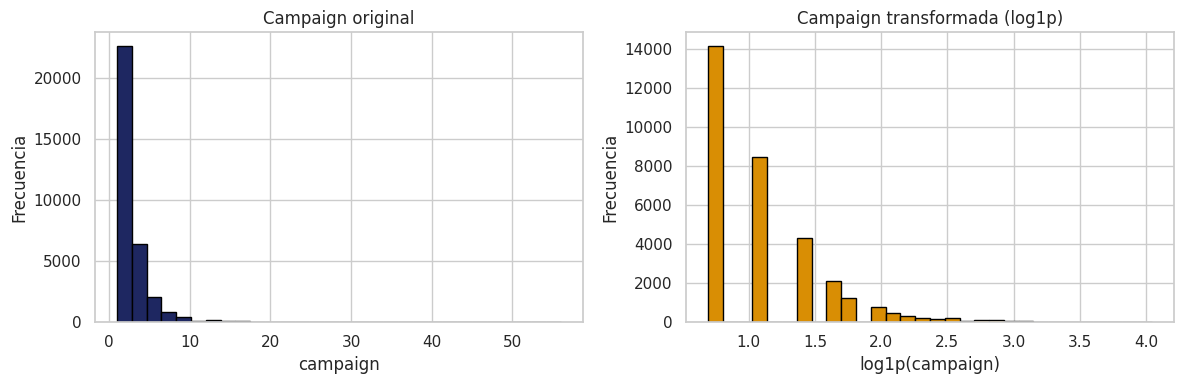

In [11]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

# Asimetría original y transformaciones
asimetria = pd.DataFrame({
    "Original": [
        ent["age"].skew(),
        ent["duration"].skew(),
        ent["campaign"].skew()
    ],
    "Raiz_cuadrada": [
        np.sqrt(ent["age"]).skew(),
        np.sqrt(ent["duration"]).skew(),
        np.sqrt(ent["campaign"]).skew()
    ],
    "Log1p": [
        np.log1p(ent["age"]).skew(),
        np.log1p(ent["duration"]).skew(),
        np.log1p(ent["campaign"]).skew()
    ]
},
index=["age", "duration", "campaign"])

print("Asimetría de las variables:")
print(asimetria.round(3))

# Histogramas de campaign: original y transformada
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Original
axes[0].hist(ent["campaign"], bins=30, color=AZUL, edgecolor="black")
axes[0].set_title("Campaign original")
axes[0].set_xlabel("campaign")
axes[0].set_ylabel("Frecuencia")

# Transformada (log1p)
campaign_log = np.log1p(ent["campaign"])
axes[1].hist(campaign_log, bins=30, color=NARANJA, edgecolor="black")
axes[1].set_title("Campaign transformada (log1p)")
axes[1].set_xlabel("log1p(campaign)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Las variables age, duration y campaign presentan asimetría positiva. La transformación np.log1p redujo más la asimetría que la raíz cuadrada en los tres casos.**

**age: no requiere transformación, ya que su asimetría original 0.761 es moderada.
duration: conviene aplicar np.log1p, porque la asimetría disminuye de 3.327 a −0.430.
campaign: también conviene aplicar np.log1p, ya que reduce la asimetría de 4.743 a 1.351, mejor que la raíz cuadrada 2.163.**

Predicción correcta ya que np.log1p(campaign) redujo más la asimetría que np.sqrt(campaign).

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero que poutcome sea la variable que más se vea la diferencia entre la tasa de contratación y categorías, especialmente porque success debería presentar una tasa de contratación mayor que failure y nonexistent.Las diferencias relevantes en contact, month y education. En cambio, day_of_week, housing y loan probablemente separen poco las clases y tengan tasas de contratación cercanas a la tasa global ~11%.**

In [15]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.
# Número de categorías por variable categórica
num_categorias = ent[categoricas].nunique().sort_values()

print("Número de categorías por variable:")
print(num_categorias)

# Tasa global de contratación
tasa_global = (ent["y"] == "yes").mean() * 100

print(f"\nTasa global de contratación: {tasa_global:.2f}%")

Número de categorías por variable:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa global de contratación: 11.27%


In [16]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.
# Construir tabla con número de clientes y tasa de contratación por categoría

tabla_cat = (
    ent[categoricas + ["suscribe"]]
    .melt(id_vars="suscribe",
          value_vars=categoricas,
          var_name="variable",
          value_name="categoria")
    .groupby(["variable", "categoria"])
    .agg(
        clientes=("suscribe", "size"),
        tasa_contratacion=("suscribe", "mean")
    )
    .reset_index()
)

tabla_cat["tasa_contratacion"] = tabla_cat["tasa_contratacion"] * 100

# 12 categorías con mayor tasa de contratación
print("=== 12 categorías con mayor tasa de contratación ===")
print(
    tabla_cat.sort_values("tasa_contratacion", ascending=False)
             .head(12)
             .round(2)
)

# 8 categorías con menor tasa de contratación
print("\n=== 8 categorías con menor tasa de contratación ===")
print(
    tabla_cat.sort_values("tasa_contratacion", ascending=True)
             .head(8)
             .round(2)
)

# Tablas específicas solicitadas
for var in ["default", "housing", "loan", "day_of_week"]:
    print(f"\n=== {var.upper()} ===")
    print(
        tabla_cat[tabla_cat["variable"] == var]
        .sort_values("tasa_contratacion", ascending=False)
        .round(2)
    )

=== 12 categorías con mayor tasa de contratación ===
     variable   categoria  clientes  tasa_contratacion
52   poutcome     success      1105              64.89
42      month         dec       143              50.35
45      month         mar       436              49.77
49      month         sep       464              44.61
48      month         oct       587              43.27
29        job     student       711              30.52
26        job     retired      1366              25.48
40      month         apr      2085              20.48
14  education  illiterate        16              18.75
39    marital     unknown        65              16.92
17  education     unknown      1397              14.82
0     contact    cellular     20908              14.70

=== 8 categorías con menor tasa de contratación ===
     variable    categoria  clientes  tasa_contratacion
9     default          yes         3               0.00
8     default      unknown      6940               5.20
1     conta

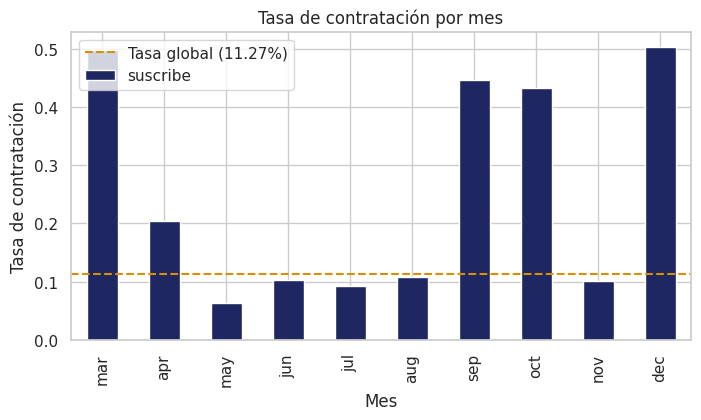

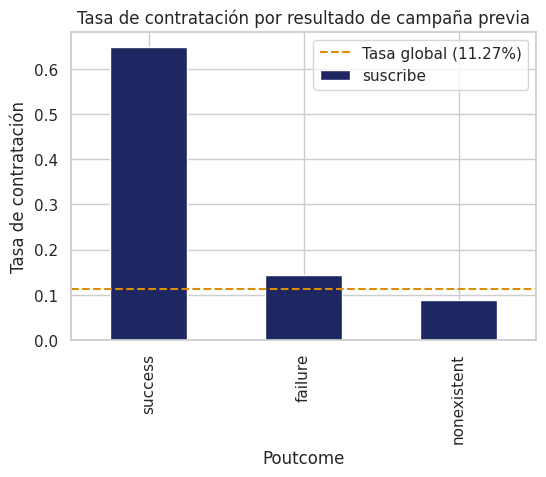

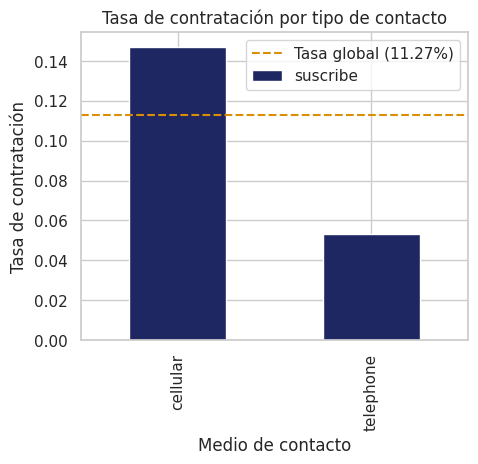

In [14]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

# E3. Tasa de contratación global
tasa_global = ent["suscribe"].mean()

# Orden cronológico de los meses
orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

# Tasa de contratación por month
tasa_month = ent.groupby("month")["suscribe"].mean().reindex(orden_meses)

plt.figure(figsize=(8, 4))
tasa_month.plot(kind="bar", color=AZUL)
plt.axhline(tasa_global, color=NARANJA, linestyle="--", label=f"Tasa global ({tasa_global:.2%})")
plt.title("Tasa de contratación por mes")
plt.ylabel("Tasa de contratación")
plt.xlabel("Mes")
plt.legend()
plt.show()

# Tasa de contratación por poutcome
tasa_poutcome = ent.groupby("poutcome")["suscribe"].mean().sort_values(ascending=False)

plt.figure(figsize=(6, 4))
tasa_poutcome.plot(kind="bar", color=AZUL)
plt.axhline(tasa_global, color=NARANJA, linestyle="--", label=f"Tasa global ({tasa_global:.2%})")
plt.title("Tasa de contratación por resultado de campaña previa")
plt.ylabel("Tasa de contratación")
plt.xlabel("Poutcome")
plt.legend()
plt.show()

# Tasa de contratación por contact
tasa_contact = ent.groupby("contact")["suscribe"].mean().sort_values(ascending=False)

plt.figure(figsize=(5, 4))
tasa_contact.plot(kind="bar", color=AZUL)
plt.axhline(tasa_global, color=NARANJA, linestyle="--", label=f"Tasa global ({tasa_global:.2%})")
plt.title("Tasa de contratación por tipo de contacto")
plt.ylabel("Tasa de contratación")
plt.xlabel("Medio de contacto")
plt.legend()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

**poutcome fue la variable con mayor capacidad de separación, especialmente la categoría success, cuya tasa de contratación fue muy superior a la tasa global 11.27%. También destaca month, contact y algunas categorías de job y education.**

**A diferencia de  day_of_week, housing y loan  que mostraron tasas de contratación similares entre sus categorías y cercanas a la tasa global, por lo que tienen poca capacidad para diferenciar entre clientes que contratan y los que no.**

**la predicción fue correcta ya que  poutcome resultó ser una de las variables más útiles para separar las clases, mientras que housing, loan y day_of_week aportaron poca diferenciación.**

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

**La categoría unknown en default puede aportar información propia. Si su tasa de contratación es diferente, puede tener valor predictivo.**

**En cambio, categorías poco frecuentes como default = yes o education = illiterate pueden tener pocos registros sus tasas y ser poco confiables.**

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Que las variables de macro presenten correlaciones altas entre sí, especialmente euribor3m, emp.var.rate y nr.employed, ya que reflejan condiciones económicas relacionadas. También  que cons.conf.idx tenga correlaciones más menores con algunas de las demás variables macroeconómicas.**

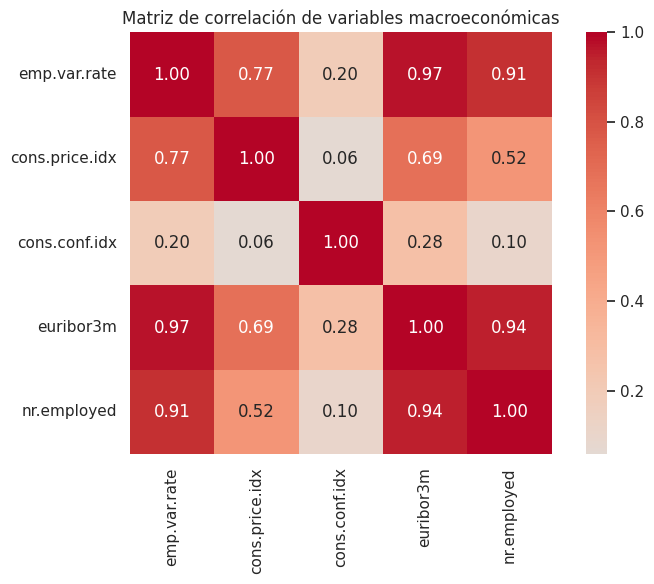

In [17]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.
# Matriz de correlación de las variables macroeconómicas
corr_macro = ent[macro].corr()

# Mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_macro,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Matriz de correlación de variables macroeconómicas")
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Los pares con mayor correlación fueron emp.var.rate y euribor3m 0.97, euribor3m y nr.employed 0.94 y emp.var.rate y nr.employed 0.91. También se observaron correlaciones moderadas entre emp.var.rate y cons.price.idx 0.77 y cons.price.idx y euribor3m 0.69.**

**Mi predicción fue correcta, ya que euribor3m, emp.var.rate y nr.employed resultaron ser las variables más correlacionadas.**

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

**No deberia utilizarse la variable duration, porque representa la duración de la llamada y solo se conoce cuando la llamada ya terminó. Como la contratación ocurre al finalizar la llamada.**

In [18]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

# Resumen estadístico de duration por clase de y
print("Resumen estadístico de duration por clase:")
print(ent.groupby("y")["duration"].describe())

Resumen estadístico de duration por clase:
       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

**Como lo comente anteriormente, no incluiría duration en el modelo, porque su valor solo se conoce después de que termina la llamada. Usarla generaría fuga de información y no estaría disponible al momento de decidir a qué clientes contactar.**

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.


**La división aleatoria produce conjuntos de entrenamiento y prueba con distribuciones similares, pero en este caso mezcla registros de diferentes fechas. Como las variables económicas cambian con el tiempo, esto puede generar una estimación optimista del desempeño del modelo. Para predecir sería adecuado usar una división temporal, entrenando con datos antiguos y evaluando con los más recientes.**

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| **duration** tiene una mediana de **448 s** en *yes* y **164 s** en *no*. | Excluir **duration** del modelo porque solo se conoce después de terminar la llamada y produciría fuga de información. | Preprocesamiento |
| **default** contiene **8,597 valores unknown (20.87%)**. | Mantener **unknown** como categoría propia y no imputar ni eliminar registros. | Preprocesamiento |
| **pdays = 999** aparece en **39,673 filas (96.32%)** y representa un código especial. | Tratar 999 como valor especial o crear una variable indicadora de contacto previo. | Preprocesamiento |
| Existen **12 filas completamente duplicadas**. | Evaluar eliminar los registros duplicados antes del modelado. | Preprocesamiento |
| La clase positiva representa **11.27%** y la negativa **88.73%** de los clientes. | Considerar técnicas para manejar el desbalance de clases. | Modelos |
| Un modelo que siempre prediga **"no"** lograría una exactitud de **88.73%**. | Utilizar métricas adicionales como precisión, recall y F1, además de accuracy. | Evaluación |
| **emp.var.rate** y **euribor3m** tienen correlación **0.97**; **euribor3m** y **nr.employed**, **0.94**. | Revisar colinealidad y considerar reducir variables redundantes en modelos lineales. | Modelos |
| La asimetría de **campaign** disminuye de **4.743** a **1.351** con **np.log1p**. | Considerar transformación logarítmica para modelos sensibles a la distribución. | Preprocesamiento |
| La asimetría de **duration** disminuye de **3.327** a **−0.430** con **np.log1p**. | La transformación logarítmica sería adecuada, aunque la variable será excluida por fuga de información. | Preprocesamiento |
| **poutcome** muestra las mayores diferencias de contratación entre categorías. | Conservar la variable por su posible capacidad predictiva. | Modelos |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

**La descripción de los datos y la detección de problemas de calidad  se realizaron con el conjunto completo df, ya que solo implican revisar estructura, valores faltantes, duplicados y consistencia de los datos.**

**la parte C, todos los análisis relacionados con la variable objetivo y las decisiones de preprocesamiento se realizaron únicamente con entrenamiento (ent)**.

**El criterio fue evitar la fuga de información, manteniendo el conjunto de prueba independiente y reservado para la evaluación final del modelo.**

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

**Si se hubiera explorado el conjunto de prueba, decisiones como la selección de variables, las transformaciones de las categorías podrían haber quedado sesgadas por información que debía reservarse para la evaluación final. Esto generaría fuga de información, haciendo que el desempeño del modelo pareciera mejor de lo que realmente sería al aplicarlo a datos nuevos. Por ello, todas las decisiones se tomaron únicamente con el conjunto de entrenamiento.**